
# Метод наименьших квадратов

Нужно реализовать метод наименьших квадратов для нахождения полинома степени не выше третьей, приближающего заданный набор точек. Использовать технологию OpenMP для параллельного выполнения вычислений

## задача

Пусть задан набор из $n$ точек:

$$
(x_1,y_1), (x_2,y_2), \ldots, (x_n,y_n)
$$

Необходимо найти полином вида:

$$
P_m(x) = a_0 + a_1x + a_2x^2 + \ldots + a_mx^m,
$$

где $0 \leq m \leq 3$

Коэффициенты полинома определяются методом наименьших квадратов, то есть путём минимизации суммы квадратов отклонений:

$$
S = \sum_{i=1}^{n} \left(y_i - P_m(x_i)\right)^2
$$

Для решения задачи нам нужно:

1. Считать координаты исходных точек
2. Построить систему нормальных уравнений
3. Вычислить необходимые суммы параллельно с использованием OpenMP
4. Решить систему линейных уравнений методом Гаусса
5. Определить коэффициенты полиномов степеней от 0 до 3
6. Вычислить ошибки приближения и выбрать наиболее подходящий полином


In [30]:
%%writefile points.txt
5
0 1
1 3
2 7
3 13
4 21

Writing points.txt


## Математический алгоритм

Коэффициенты полинома находятся из **системы нормальных уравнений**:

$$
\sum_{j=0}^{m} a_j \left(\sum_{k=1}^{n}x_k^{i+j}\right)
=\sum_{k=1}^{n}y_kx_k^i,\qquad i=0,\ldots,m
$$

Обозначим

$$
A_{ij}=\sum_{k=1}^{n}x_k^{i+j},\qquad
b_i=\sum_{k=1}^{n}y_kx_k^i
$$

Тогда решаем систему $Aa=b$ методом Гаусса с выбором ведущей строки

При $m\le3$ максимальная степень $x$ в матрице $A$ равна 6. Поэтому достаточно вычислить суммы $\sum x_k^p$ для $p=0,\ldots,6$ и $\sum y_kx_k^p$ для $p=0,\ldots,3$

Где используется OpenMP: при вычислении этих сумм и при расчёте суммы квадратов ошибок. Директива `#pragma omp parallel for reduction(...)` распределяет итерации цикла между потоками и безопасно объединяет промежуточные суммы


In [31]:
%%writefile mnk.cpp
#include <iostream>
#include <fstream>
#include <vector>
#include <cmath>
#include <iomanip>
#include <algorithm>
#include <limits>
#include <omp.h>

//одна точка (x, y)
struct Point {double x, y;};

//чтение точек: сначала количество, затем пары x y
bool readPoints(const std::string& filename, std::vector<Point>& points) {
    std::ifstream file(filename);
    int n;
    if (!(file >> n) || n <= 0) {
        std::cerr << "Error: cannot read point count from " << filename << '\n';
        return false;
    }
    points.resize(n);
    for (int i = 0; i < n; ++i) {
        if (!(file >> points[i].x >> points[i].y) ||
            !std::isfinite(points[i].x) || !std::isfinite(points[i].y)) {
            std::cerr << "Error: invalid point " << i + 1 << '\n';
            return false;
        }
    }
    return true;
}

//суммы x^k (k=0..6) и y*x^k (k=0..3) для нормальных уравнений
void calculateSums(const std::vector<Point>& points,double (&sumX)[7], double (&sumXY)[4]) {
    int n = static_cast<int>(points.size());

    //reduction: каждый поток собирает свои суммы, затем они объединяются
    #pragma omp parallel for reduction(+:sumX[:7],sumXY[:4])
    for (int i = 0; i < n; ++i) {
        double power = 1.0;
        for (int k = 0; k <= 6; ++k) {
            sumX[k] += power;
            if (k <= 3) sumXY[k] += points[i].y * power;
            power *= points[i].x;
        }
    }
}

//решаем Ax=b методом Гаусса с выбором ведущей строки
bool gaussianElimination(std::vector<std::vector<double>> A, std::vector<double> b, std::vector<double>& coefficients) {
    int n = static_cast<int>(b.size());
    for (int k = 0; k < n; ++k) {
        int pivot = k;
        for (int i = k + 1; i < n; ++i) {
            if (std::fabs(A[i][k]) > std::fabs(A[pivot][k])) pivot = i;
        }
        if (std::fabs(A[pivot][k]) < 1e-12) return false;
        std::swap(A[k], A[pivot]);
        std::swap(b[k], b[pivot]);

        for (int i = k + 1; i < n; ++i) {
            double factor = A[i][k] / A[k][k];
            for (int j = k; j < n; ++j) A[i][j] -= factor * A[k][j];
            b[i] -= factor * b[k];
        }
    }

    coefficients.assign(n, 0.0);
    for (int i = n - 1; i >= 0; --i) {
        double value = b[i];
        for (int j = i + 1; j < n; ++j) value -= A[i][j] * coefficients[j];
        coefficients[i] = value / A[i][i];
    }
    return true;
}

//значение полинома по схеме Горнера a[0] + a[1]*x + a[2]*x^2 + ...
double polynomial(double x, const std::vector<double>& a) {
    double y = 0.0;
    for (int j = static_cast<int>(a.size()) - 1; j >= 0; --j) {
        y = y * x + a[j];
    }
    return y;
}

//сумма квадратов ошибок (параллельный расчёт)
double squaredError(const std::vector<Point>& points,
                    const std::vector<double>& a) {
    double error = 0.0;
    int n = static_cast<int>(points.size());
    #pragma omp parallel for reduction(+:error)
    for (int i = 0; i < n; ++i) {
        double diff = points[i].y - polynomial(points[i].x, a);
        error += diff * diff;
    }
    return error;
}

void printPolynomial(const std::vector<double>& a) {
    std::cout << "P(x) = " << a[0];
    for (int j = 1; j < static_cast<int>(a.size()); ++j) {
        if (std::fabs(a[j]) < 1e-8) continue;
        std::cout << (a[j] < 0 ? " - " : " + ") << std::fabs(a[j]) << "*x";
        if (j > 1) std::cout << "^" << j;
    }
    std::cout << '\n';
}

int main() {
    std::vector<Point> points;
    if (!readPoints("points.txt", points)) return 1;

    double sumX[7] = {};
    double sumXY[4] = {};
    calculateSums(points, sumX, sumXY);

    //нельзя определять больше коэффициентов, чем имеется точек
    int maxDegree = std::min(3, static_cast<int>(points.size()) - 1);
    double yScale = 0.0;
    for (const Point& p : points) yScale += p.y * p.y;
    double tolerance = 1e-10 * std::max(1.0, yScale);

    double bestError = std::numeric_limits<double>::infinity();
    int bestDegree = -1;
    std::vector<double> bestCoefficients;

    std::cout << std::fixed << std::setprecision(6);
    std::cout << "Points: " << points.size() << '\n';
    std::cout << "OpenMP max threads: " << omp_get_max_threads() << "\n\n";

    for (int degree = 0; degree <= maxDegree; ++degree) {
        int size = degree + 1;
        std::vector<std::vector<double>> A(size, std::vector<double>(size));
        std::vector<double> b(size);

        //система нормальных уравнений: A[i][j]=sum(x^(i+j)), b[i]=sum(y*x^i)
        for (int i = 0; i < size; ++i) {
            b[i] = sumXY[i];
            for (int j = 0; j < size; ++j) A[i][j] = sumX[i + j];
        }

        std::vector<double> a;
        if (!gaussianElimination(A, b, a)) {
            std::cout << "Degree " << degree << ": singular system\n\n";
            continue;
        }

        double error = squaredError(points, a);
        std::cout << "Degree " << degree << ": ";
        printPolynomial(a);
        std::cout << "SSE = " << error << "\n\n";

        //если ошибки практически равны, оставляем меньшую степень
        if (bestDegree == -1 || error < bestError - tolerance) {
            bestError = error;
            bestDegree = degree;
            bestCoefficients = a;
        }
    }

    if (bestDegree == -1) {
        std::cerr << "Error: no polynomial found\n";
        return 1;
    }

    std::cout << "BEST POLYNOMIAL (degree " << bestDegree << "):\n";
    printPolynomial(bestCoefficients);
    std::cout << "SSE = " << bestError << "\n\n";

    //выводим только первые 10 точек

    int count = std::min(10, static_cast<int>(points.size()));

    std::cout << "\nComparison (first " << count << " of " << points.size() << " points):\n";

    //показываем исходное и рассчитанное значение
    for (int i = 0; i < count; ++i) {
        const Point& p = points[i];
        std::cout << p.x << "  " << p.y << "  " << polynomial(p.x, bestCoefficients) << '\n';
    }

    //сохраняем коэффициенты, чтобы построить график в JupyterLab
    std::ofstream result("result.txt");
    if (!result) {
        std::cerr << "Error: cannot create result.txt\n";
        return 1;
    }
    result << bestDegree << '\n' << std::setprecision(17);
    for (double a : bestCoefficients) result << a << ' ';
    result << '\n' << bestError << '\n';
    return 0;
}

Writing mnk.cpp


Компиляция

Сохраняем основной код на C++ в файл `mnk.cpp` и компилируем его командой `g++`

- `-std=c++17` — стандарт C++17
- `-O2` — оптимизация
- `-fopenmp` — включение OpenMP
- `-o mnk.exe` — имя исполняемого файла

In [32]:
!g++ -std=c++17 -O2 -fopenmp mnk.cpp -o mnk.exe

Запуск и анализ результатов

Программа читает точки из `points.txt`, строит полиномы допустимых степеней, выводит коэффициенты и показатель **SSE** (Sum of Squared Errors) — сумму квадратов ошибок

Чем меньше SSE, тем лучше полином приближает данные. Если SSE практически равна нулю, полином проходит через все исходные точки с точностью машинных вычислений

Для нашего тестового набора ожидаем результат $P(x)=x^2+x+1$ со степенью 2. Программа также сохраняет найденные коэффициенты в `result.txt` для построения графика


In [34]:
!.\mnk.exe

Points: 5
OpenMP max threads: 8

Degree 0: P(x) = 9.000000
SSE = 264.000000

Degree 1: P(x) = -1.000000 + 5.000000*x
SSE = 14.000000

Degree 2: P(x) = 1.000000 + 1.000000*x + 1.000000*x^2
SSE = 0.000000

Degree 3: P(x) = 1.000000 + 1.000000*x + 1.000000*x^2
SSE = 0.000000

BEST POLYNOMIAL (degree 2):
P(x) = 1.000000 + 1.000000*x + 1.000000*x^2
SSE = 0.000000


Comparison (first 5 of 5 points):
0.000000  1.000000  1.000000
1.000000  3.000000  3.000000
2.000000  7.000000  7.000000
3.000000  13.000000  13.000000
4.000000  21.000000  21.000000


Построим график найденного полинома и нанесём исходные точки

Для графика требуется пакет `matplotlib`. Если появится `ModuleNotFoundError`, один раз выполни в отдельной Code-ячейке `%pip install matplotlib`, затем снова запусти ячейку с графиком.


In [17]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


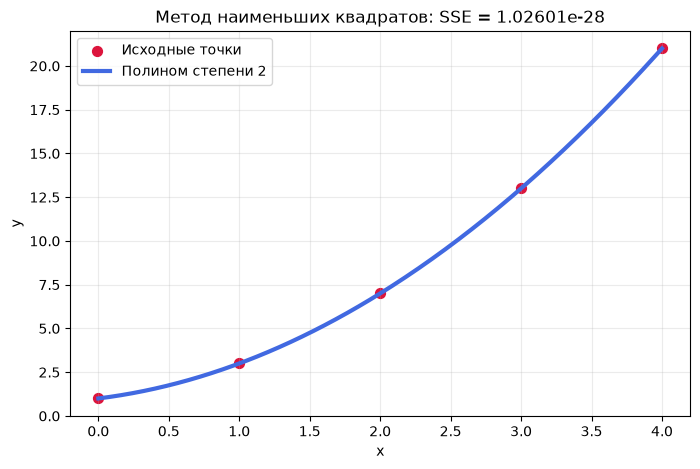

In [40]:
import matplotlib.pyplot as plt

#читаем исходные точки из файла, созданного в начале работы
with open("points.txt", encoding="utf-8") as file:
    n = int(file.readline())
    points = [tuple(map(float, file.readline().split())) for _ in range(n)]

#читаем коэффициенты, которые вычислила программа на C++
with open("result.txt", encoding="utf-8") as file:
    degree = int(file.readline())
    coefficients = list(map(float, file.readline().split()))
    sse = float(file.readline())

#значение найденного полинома
#здесь формула нужна только для рисования графика
def polynomial_for_plot(x):
    return sum(a * x**i for i, a in enumerate(coefficients))

xs = [point[0] for point in points]
ys = [point[1] for point in points]

#строим гладкую линию по 300 значениям x
x_min, x_max = min(xs), max(xs)
if x_min == x_max:
    x_min -= 1
    x_max += 1
x_plot = [x_min + (x_max - x_min) * i / 299 for i in range(300)]
y_plot = [polynomial_for_plot(x) for x in x_plot]

plt.figure(figsize=(8, 5))
#исходные точки
plt.scatter(
    xs, ys,
    color="crimson",
    #s=2,
    s=50,
    #alpha=0.08,
    alpha=1,
    label="Исходные точки",
    zorder=1,
    rasterized=True
)

#полином
plt.plot(
    x_plot, y_plot,
    color="royalblue",
    linewidth=3,
    label=f"Полином степени {degree}",
    zorder=3
)
plt.title(f"Метод наименьших квадратов: SSE = {sse:.6g}")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(alpha=0.25)
plt.legend()
plt.show()


## Вывод

В лабораторной работе реализован метод наименьших квадратов на C++ с поддержкой OpenMP. По заданным точкам формировалась система нормальных уравнений, решалась методом Гаусса и вычислялась сумма квадратов отклонений

для тестовых точек $(0,1)$, $(1,3)$, $(2,7)$, $(3,13)$ и $(4,21)$ найден полином

$$
\boxed{P(x)=x^2+x+1}.
$$

Ошибка SSE практически равна нулю. При одинаковой точности был выбран полином второй степени, а не более сложный полином третьей степени

OpenMP применялся для параллельного накопления сумм и вычисления ошибки. **На пяти точках ускорение не обязательно заметно**, поскольку запуск потоков сам по себе требует времени. Для больших наборов данных параллельные вычисления могут быть полезнее.

*Ограничение метода:* нормальные уравнения могут быть численно неустойчивыми на больших координатах или плохо обусловленных данных
